In [ ]:
# PALMER PENGUINS — ANALISI ESPLORATIVA E PREPARAZIONE DATI
# Componente 1 — Modelli e principi della percezione

# 1. IMPORTAZIONE LIBRERIE

from pathlib import Path
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler


# 2. CARICAMENTO DEL DATASET

# Percorsi possibili: repository GitHub
cartelle_possibili = [
    Path("data/raw"),
    Path("../data/raw"),
    Path("data/processed"),
    Path("../data/processed"),
    Path("data_processed"),
    Path(".")
]

file_grezzo = next(
    (p / "penguins_lter.csv" for p in cartelle_possibili if (p / "penguins_lter.csv").is_file()),
    None
)
file_pulito = next(
    (p / "penguins_metadata_eval.csv" for p in cartelle_possibili if (p / "penguins_metadata_eval.csv").is_file()),
    None
)

if file_grezzo is not None:
    sorgente = file_grezzo
    df_raw = pd.read_csv(file_grezzo)
elif file_pulito is not None:
    sorgente = file_pulito
    df_raw = pd.read_csv(file_pulito)
else:
    raise FileNotFoundError(
        "Caricare penguins_lter.csv (oppure penguins_metadata_eval.csv) in Colab "
        "o inserirlo nella cartella data/raw o data/processed del repository."
    )

# Individuiamo la cartella principale del progetto
cartella_dati = sorgente.parent
if cartella_dati.name in ("raw", "processed") and cartella_dati.parent.name == "data":
    ROOT = cartella_dati.parent.parent
elif cartella_dati.name == "data_processed":
    ROOT = cartella_dati.parent
else:
    ROOT = Path(".")

# Le 4 feature morfometriche numeriche su cui lavorerà Mean-Shift
features = [
    "Culmen Length (mm)",
    "Culmen Depth (mm)",
    "Flipper Length (mm)",
    "Body Mass (g)"
]

print("File caricato:", sorgente)
print("Dimensioni iniziali:", df_raw.shape)


# 3. ISPEZIONE INIZIALE E PULIZIA MIRATA

df_lavoro = df_raw.copy()

# Salviamo l'indice di riga originale prima della pulizia
if "Original_Row_Index" not in df_lavoro.columns:
    df_lavoro.insert(0, "Original_Row_Index", np.arange(len(df_lavoro)))

# Controllo valori mancanti nelle colonne principali
print("\n--- VALORI MANCANTI INIZIALI ---")
colonne_audit = [c for c in features + ["Sex", "Island", "Species"] if c in df_lavoro.columns]
print(df_lavoro[colonne_audit].isna().sum())

# Correzione dell'anomalia "." nella colonna Sex
n_anomalie_sex = 0
if "Sex" in df_lavoro.columns:
    n_anomalie_sex = int((df_lavoro["Sex"] == ".").sum())
    df_lavoro["Sex"] = df_lavoro["Sex"].replace(".", np.nan)
    print(f"\nAnomalie '.' corrette in Sex: {n_anomalie_sex}")

# Pulizia mirata: rimuoviamo solo le righe prive delle 4 misure fisiche.
# Non eliminiamo i NaN in Sex per non perdere esemplari con misure complete.
righe_scartate = df_lavoro[df_lavoro[features].isna().any(axis=1)]["Original_Row_Index"].tolist()
df_pulito = df_lavoro.dropna(subset=features).reset_index(drop=True)

# Nome breve della specie (usato solo per l'EDA, escluso dal clustering)
df_pulito["Species_Short"] = df_pulito["Species"].str.split(" ").str[0]

print("\n--- RIEPILOGO PULIZIA ---")
print("Righe iniziali:", len(df_lavoro))
print("Righe scartate (indici originali):", righe_scartate)
print("Righe pulite conservate:", len(df_pulito))
if "Sex" in df_pulito.columns:
    print("Pinguini conservati con Sex mancante:", int(df_pulito["Sex"].isna().sum()))


# 4. ANALISI ESPLORATIVA (EDA)

print("\n--- COMPOSIZIONE PER SPECIE ---")
print(df_pulito["Species_Short"].value_counts())

print("\n--- DISTRIBUZIONE ISOLA x SPECIE ---")
tab_isole = pd.crosstab(df_pulito["Island"], df_pulito["Species_Short"])
print(tab_isole)

print("\n--- STATISTICHE DESCRITTIVE GLOBALI ---")
print(df_pulito[features].describe().loc[["mean", "std", "min", "50%", "max"]].round(2))

print("\n--- MEDIE PER SPECIE (SOLO ESPLORATIVO) ---")
print(df_pulito.groupby("Species_Short")[features].mean().round(2))

print("\n--- MATRICE DI CORRELAZIONE ---")
corr = df_pulito[features].corr()
print(corr.round(3))


# 5. STANDARDIZZAZIONE (Z-SCORE)

# Standardizziamo le 4 feature (media = 0, deviazione standard = 1)
# perché Body Mass (migliaia di g) e Culmen Depth (decine di mm) hanno scale diverse.
scaler = StandardScaler()
X_std = scaler.fit_transform(df_pulito[features])
df_X_std = pd.DataFrame(X_std, columns=features)

# Verifica rapida di valori estremi (|z| > 2.5)
valori_estremi = df_pulito.loc[
    (df_X_std.abs() > 2.5).any(axis=1),
    ["Original_Row_Index", "Species_Short", "Island"]
].copy()
valori_estremi["max_abs_z"] = df_X_std.loc[valori_estremi.index].abs().max(axis=1).round(2)

print("\n--- VERIFICA VALORI ESTREMI (|z| > 2.5) ---")
print(valori_estremi.to_string())


# 6. CONTROLLI SUI DATI PREPARATI

assert list(df_X_std.columns) == features
assert df_X_std.shape == (342, 4)
assert np.isfinite(X_std).all()
assert len(df_pulito) == len(df_X_std)
assert df_pulito["Original_Row_Index"].is_unique
assert np.allclose(df_X_std.mean(axis=0), 0.0, atol=1e-10)
assert np.allclose(df_X_std.std(axis=0, ddof=0), 1.0, atol=1e-10)

print("\nControlli dei dati: SUPERATI")


# 7. ESPORTAZIONE DEI DATASET

colonne_meta = [
    c for c in [
        "Original_Row_Index", "studyName", "Sample Number", "Individual ID",
        "Species", "Island", "Sex"
    ] + features if c in df_pulito.columns
]
metadata = df_pulito[colonne_meta].copy()

cartella_output = ROOT / "data" / "processed"
cartella_output.mkdir(parents=True, exist_ok=True)

df_X_std.to_csv(cartella_output / "penguins_meanshift_X_std.csv", index=False)
metadata.to_csv(cartella_output / "penguins_metadata_eval.csv", index=False)

print("\n--- ESPORTAZIONE COMPLETATA ---")
print("X standardizzato:", df_X_std.shape)
print("Metadati:", metadata.shape)
print("File salvati in:", cartella_output)


File caricato: data/processed/penguins_metadata_eval.csv
Dimensioni iniziali: (342, 11)

--- VALORI MANCANTI INIZIALI ---
Culmen Length (mm)     0
Culmen Depth (mm)      0
Flipper Length (mm)    0
Body Mass (g)          0
Sex                    9
Island                 0
Species                0
dtype: int64

Anomalie '.' corrette in Sex: 0

--- RIEPILOGO PULIZIA ---
Righe iniziali: 342
Righe scartate (indici originali): []
Righe pulite conservate: 342
Pinguini conservati con Sex mancante: 9

--- COMPOSIZIONE PER SPECIE ---
Species_Short
Adelie       151
Gentoo       123
Chinstrap     68
Name: count, dtype: int64

--- DISTRIBUZIONE ISOLA x SPECIE ---
Species_Short  Adelie  Chinstrap  Gentoo
Island                                  
Biscoe             44          0     123
Dream              56         68       0
Torgersen          51          0       0

--- STATISTICHE DESCRITTIVE GLOBALI ---
      Culmen Length (mm)  Culmen Depth (mm)  Flipper Length (mm)  Body Mass (g)
mean           

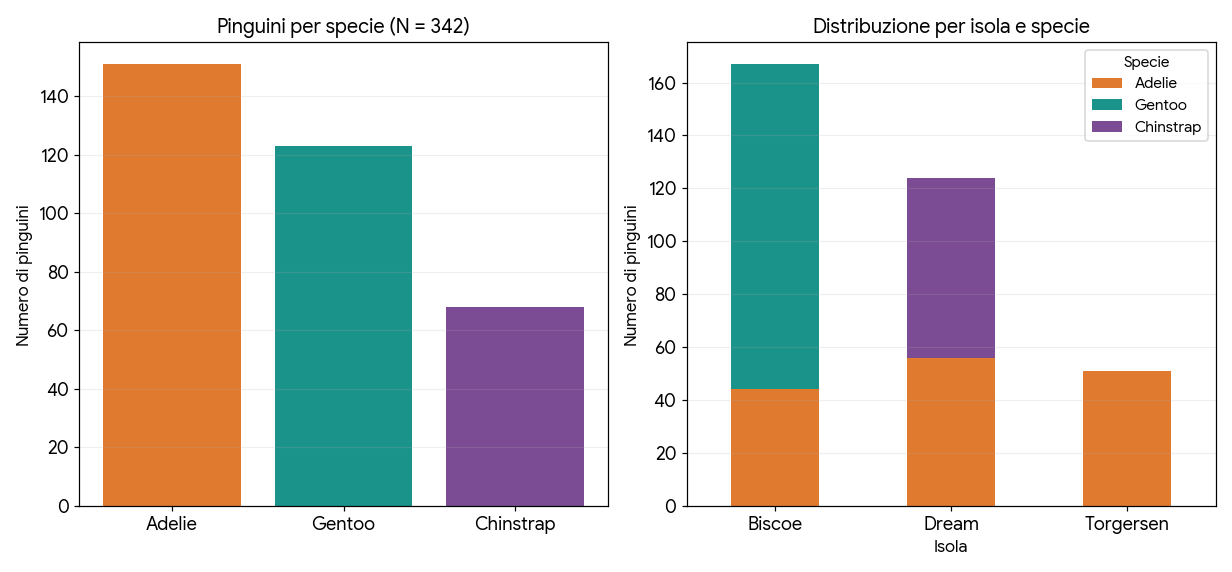

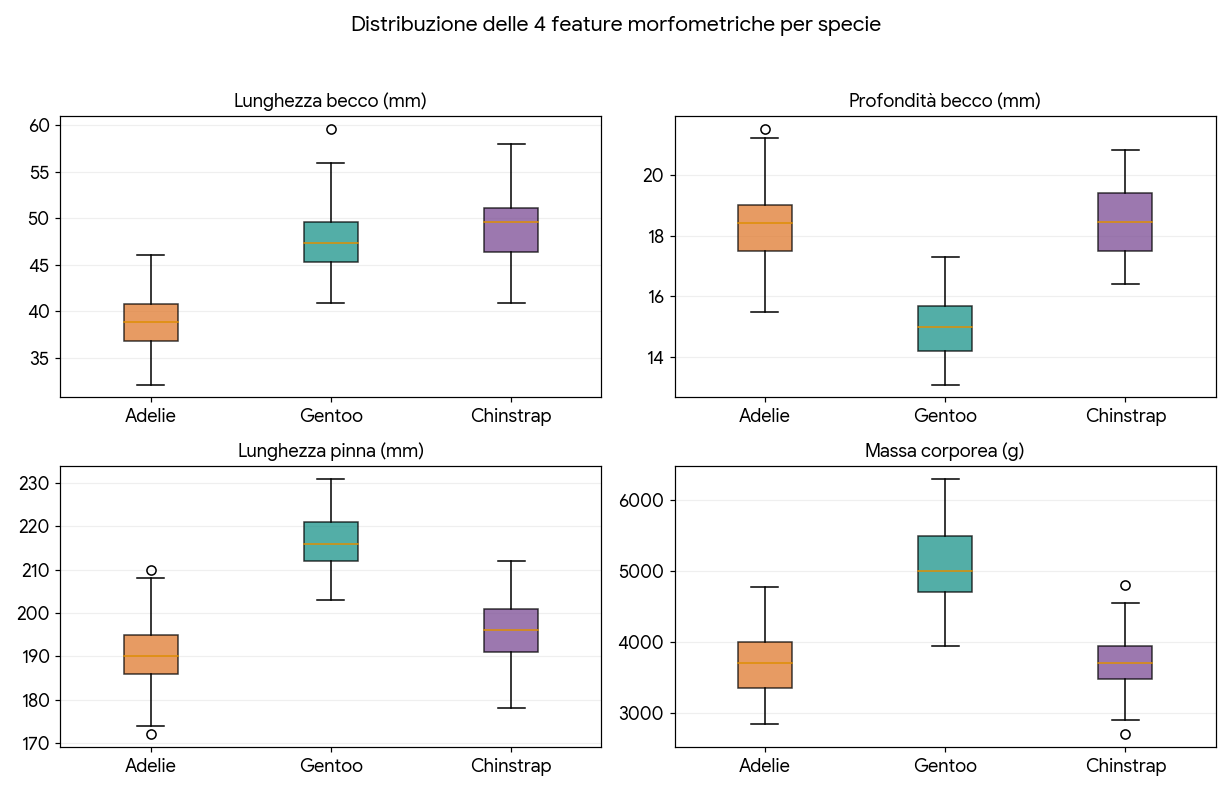

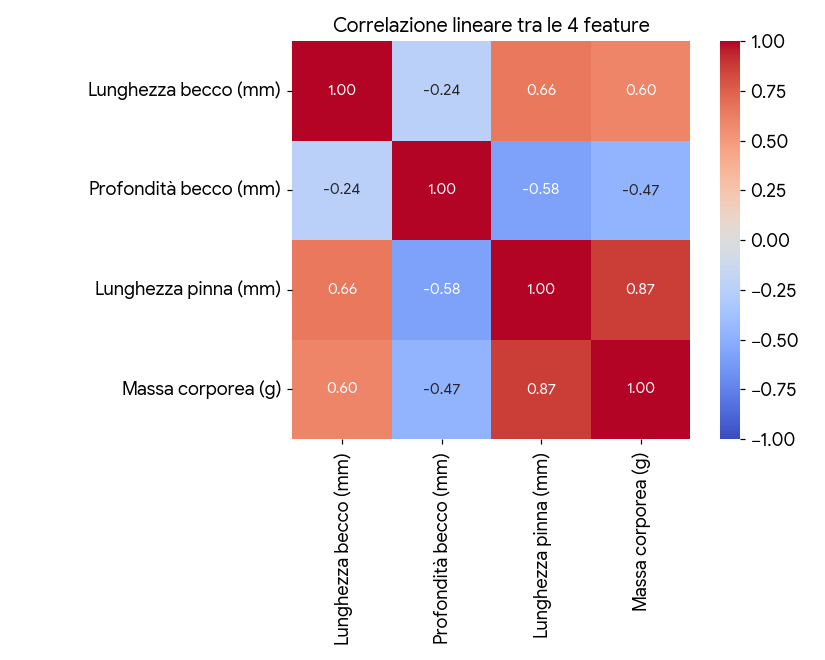

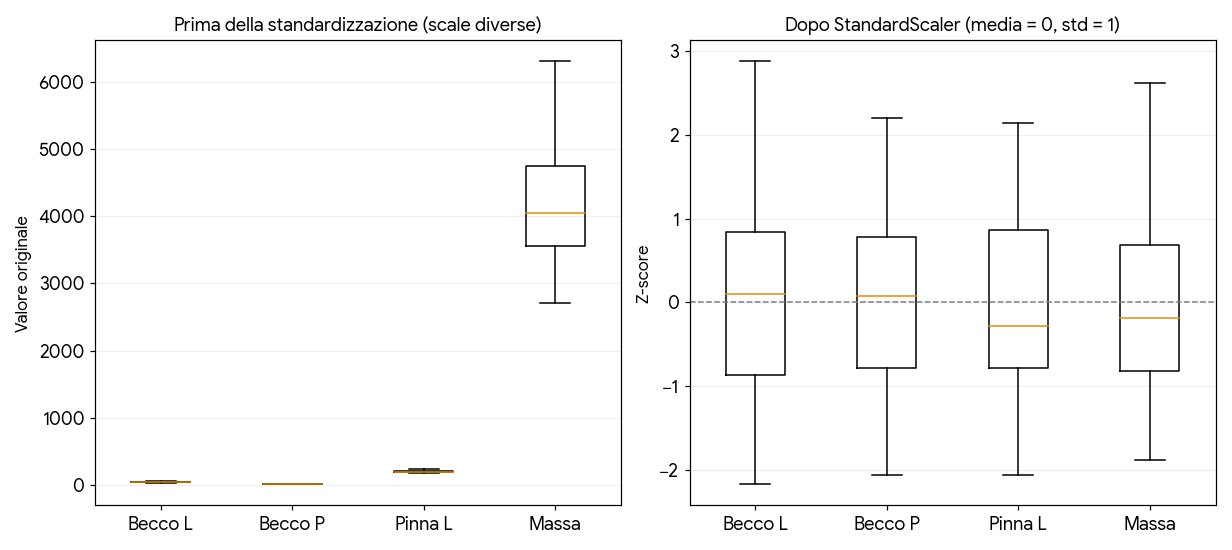


Grafici salvati in: figures/eda
Archivio ZIP: grafici_eda.zip


In [2]:
# ============================================================
# PALMER PENGUINS — VISUALIZZAZIONE DEI RISULTATI (EDA)
# ============================================================

import matplotlib.pyplot as plt
import seaborn as sns
import shutil


# 1. PREPARAZIONE CARTELLA E STILE

cartella_grafici = ROOT / "figures" / "eda"
cartella_grafici.mkdir(parents=True, exist_ok=True)

specie_ordine = ["Adelie", "Gentoo", "Chinstrap"]
colori_specie = {
    "Adelie": "#E07A2F",
    "Gentoo": "#1A938A",
    "Chinstrap": "#7B4B94"
}
nomi_it = {
    "Culmen Length (mm)": "Lunghezza becco (mm)",
    "Culmen Depth (mm)": "Profondità becco (mm)",
    "Flipper Length (mm)": "Lunghezza pinna (mm)",
    "Body Mass (g)": "Massa corporea (g)"
}


def salva_grafico(fig, nome):
    # Salva PNG (300 dpi) e SVG vettoriale (come nel notebook 02)
    fig.savefig(
        cartella_grafici / f"{nome}.png",
        dpi=300,
        facecolor="white"
    )
    fig.savefig(
        cartella_grafici / f"{nome}.svg",
        facecolor="white"
    )
    plt.show()
    plt.close(fig)


# 2. GRAFICO 1 — COMPOSIZIONE PER SPECIE E ISOLE

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.2, 5.2))

conteggi_specie = df_pulito["Species_Short"].value_counts().reindex(specie_ordine)
ax1.bar(
    specie_ordine,
    conteggi_specie.values,
    color=[colori_specie[s] for s in specie_ordine]
)
ax1.set_title(f"Pinguini per specie (N = {len(df_pulito)})", fontsize=13)
ax1.set_ylabel("Numero di pinguini")
ax1.grid(axis="y", alpha=0.2)

tab_plot = tab_isole.reindex(columns=specie_ordine, fill_value=0)
tab_plot.plot(
    kind="bar",
    stacked=True,
    ax=ax2,
    color=[colori_specie[s] for s in specie_ordine]
)
ax2.set_title("Distribuzione per isola e specie", fontsize=13)
ax2.set_xlabel("Isola")
ax2.set_ylabel("Numero di pinguini")
ax2.tick_params(axis="x", rotation=0)
ax2.grid(axis="y", alpha=0.2)
ax2.legend(title="Specie")

fig.tight_layout()
salva_grafico(fig, "01_specie_e_isole")


# 3. GRAFICO 2 — DISTRIBUZIONE DELLE 4 FEATURE PER SPECIE

fig, axes = plt.subplots(2, 2, figsize=(11.2, 7.2))

for ax, col in zip(axes.flat, features):
    dati = [df_pulito.loc[df_pulito["Species_Short"] == s, col] for s in specie_ordine]
    bp = ax.boxplot(dati, patch_artist=True)
    for patch, s in zip(bp["boxes"], specie_ordine):
        patch.set_facecolor(colori_specie[s])
        patch.set_alpha(0.75)
    ax.set_xticklabels(specie_ordine)
    ax.set_title(nomi_it[col], fontsize=12)
    ax.grid(axis="y", alpha=0.2)

fig.suptitle("Distribuzione delle 4 feature morfometriche per specie", fontsize=14)
fig.tight_layout(rect=[0, 0, 1, 0.95])
salva_grafico(fig, "02_distribuzioni_feature")


# 4. GRAFICO 3 — MATRICE DI CORRELAZIONE

fig, ax = plt.subplots(figsize=(7.5, 6.0))
corr_it = corr.rename(index=nomi_it, columns=nomi_it)

sns.heatmap(
    corr_it,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    square=True,
    ax=ax
)
ax.set_title("Correlazione lineare tra le 4 feature", fontsize=13)
fig.tight_layout()
salva_grafico(fig, "03_correlazione_feature")


# 5. GRAFICO 4 — EFFETTO DELLA STANDARDIZZAZIONE

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.2, 5.0))
etichette = ["Becco L", "Becco P", "Pinna L", "Massa"]

ax1.boxplot([df_pulito[c] for c in features])
ax1.set_xticklabels(etichette)
ax1.set_title("Prima della standardizzazione (scale diverse)", fontsize=12)
ax1.set_ylabel("Valore originale")
ax1.grid(axis="y", alpha=0.2)

ax2.boxplot([df_X_std[c] for c in features])
ax2.set_xticklabels(etichette)
ax2.axhline(0, color="gray", linestyle="--", linewidth=1)
ax2.set_title("Dopo StandardScaler (media = 0, std = 1)", fontsize=12)
ax2.set_ylabel("Z-score")
ax2.grid(axis="y", alpha=0.2)

fig.tight_layout()
salva_grafico(fig, "04_effetto_standardizzazione")


# 6. CREAZIONE ARCHIVIO ZIP

# Lo ZIP contiene PNG e SVG di tutti i grafici EDA
percorso_zip = shutil.make_archive(
    str(ROOT / "grafici_eda"),
    "zip",
    root_dir=cartella_grafici
)

print("\nGrafici salvati in:", cartella_grafici)
print("Archivio ZIP:", ROOT / "grafici_eda.zip")
